# Experiment-8

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the dataset from your local file
df = pd.read_csv("/Users/anaghbajpai/Desktop/myenv/ML_Lab_And_Practice/Datasets/Breast_Cancer/data.csv")

# Display the first few rows
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [3]:
# Extract features (X) and target (y)
# Assuming column at index 1 (second column) is the target
y = df.iloc[:, 1]  # Target variable
X = df.drop(df.columns[[0,1,32]], axis=1)  # All columns except the target

# Print shapes to verify
print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (569, 30)
Target shape: (569,)


In [4]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
# Create and train the KNN classifier
k = 5  # Number of neighbors
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train_scaled, y_train)

# Make predictions
y_pred = knn.predict(X_test_scaled)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['M', 'B']))

Accuracy: 0.9474

Classification Report:
              precision    recall  f1-score   support

           M       0.96      0.96      0.96        71
           B       0.93      0.93      0.93        43

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



# Experiment-6

In [6]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# Load the dataset
df = pd.read_csv("Datasets/Breast_Cancer/data.csv")

# Display first few rows
print(df.head())

# Check for missing values
print(df.isnull().sum())

# Encode categorical target variable
label_encoder = LabelEncoder()
df['diagnosis'] = label_encoder.fit_transform(df['diagnosis'])  # M = 1, B = 0

# Separate features and target variable
X = df.drop(df.columns[[0,1,32]], axis=1)  # All columns except the target
y = df['diagnosis']  # Target

# Normalize the feature values
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Split dataset into training (80%) and testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build the Artificial Neural Network using Input layer
model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),  # Define input shape explicitly
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(8, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')  # Output layer (binary classification)
])

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_test, y_test))

# Evaluate the model
y_pred = (model.predict(X_test) > 0.5).astype("int32")
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")
print(classification_report(y_test, y_pred))

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  smoothness

# Experiment 4

C4.5 Decision Tree Evaluation
Accuracy: 0.9473684210526315
              precision    recall  f1-score   support

           0       0.93      0.99      0.96        71
           1       0.97      0.88      0.93        43

    accuracy                           0.95       114
   macro avg       0.95      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114



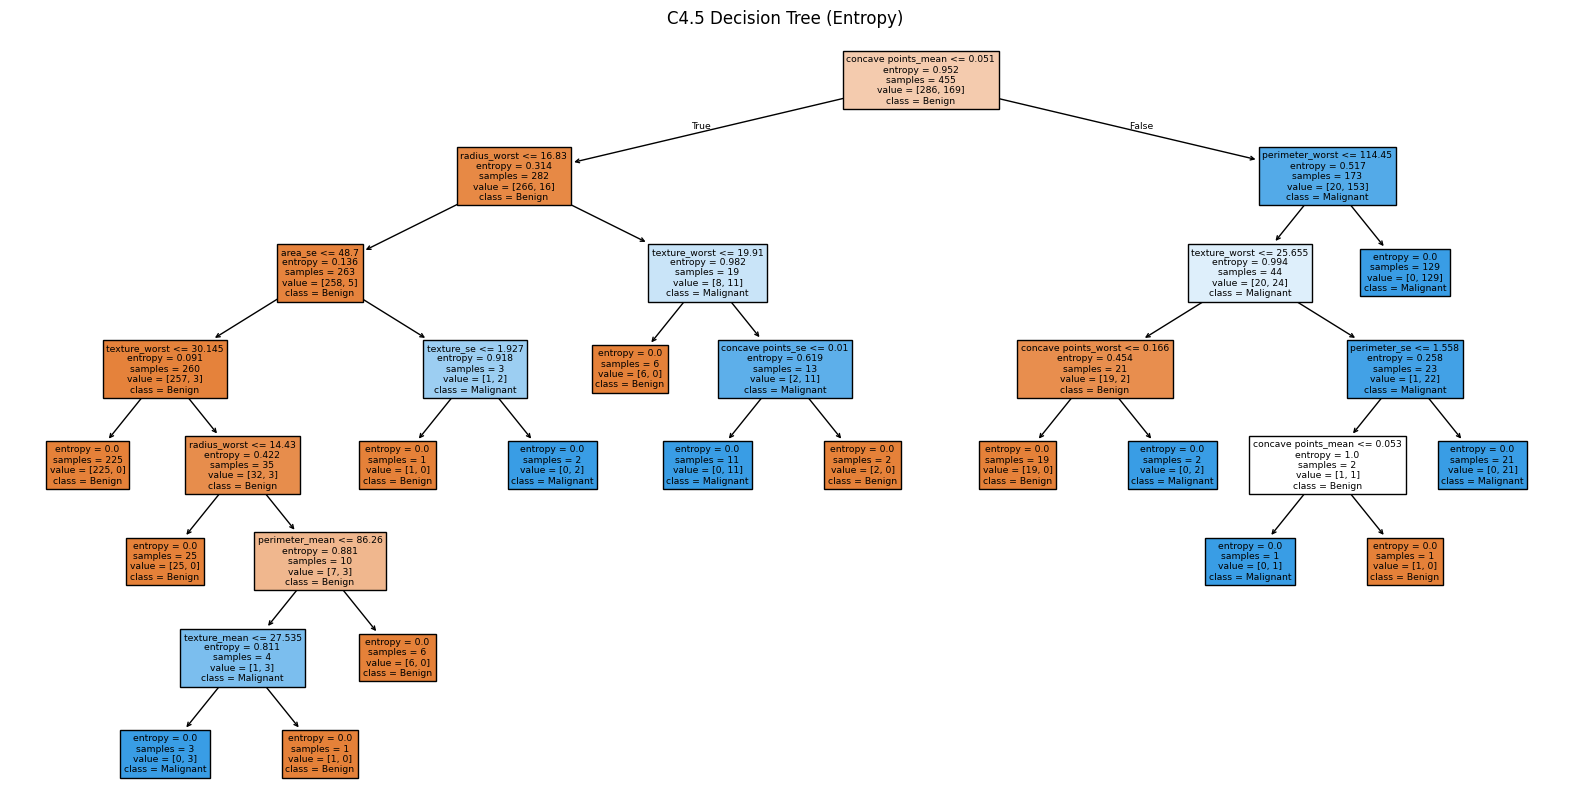

In [7]:
# Experiment 4 - C4.5 Algorithm (Entropy-based Decision Tree)
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

df = pd.read_csv("Datasets/Breast_Cancer/data.csv")
df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

# Split data
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train using C4.5 (Entropy)
c45 = DecisionTreeClassifier(criterion='entropy', random_state=42)
c45.fit(X_train, y_train)
y_pred = c45.predict(X_test)

# Evaluation
print("C4.5 Decision Tree Evaluation")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Plot the tree
plt.figure(figsize=(20, 10))
plot_tree(c45, feature_names=X.columns, class_names=['Benign', 'Malignant'], filled=True)
plt.title("C4.5 Decision Tree (Entropy)")
plt.show()

# Experiment 5

ID3 (Entropy) Evaluation
Accuracy: 0.9473684210526315
              precision    recall  f1-score   support

           0       0.93      0.99      0.96        71
           1       0.97      0.88      0.93        43

    accuracy                           0.95       114
   macro avg       0.95      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114

C4.5 Evaluation
Accuracy: 0.9473684210526315
              precision    recall  f1-score   support

           0       0.93      0.99      0.96        71
           1       0.97      0.88      0.93        43

    accuracy                           0.95       114
   macro avg       0.95      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114

CART (Gini) Evaluation
Accuracy: 0.9473684210526315
              precision    recall  f1-score   support

           0       0.96      0.96      0.96        71
           1       0.93      0.93      0.93        43

    accuracy                   

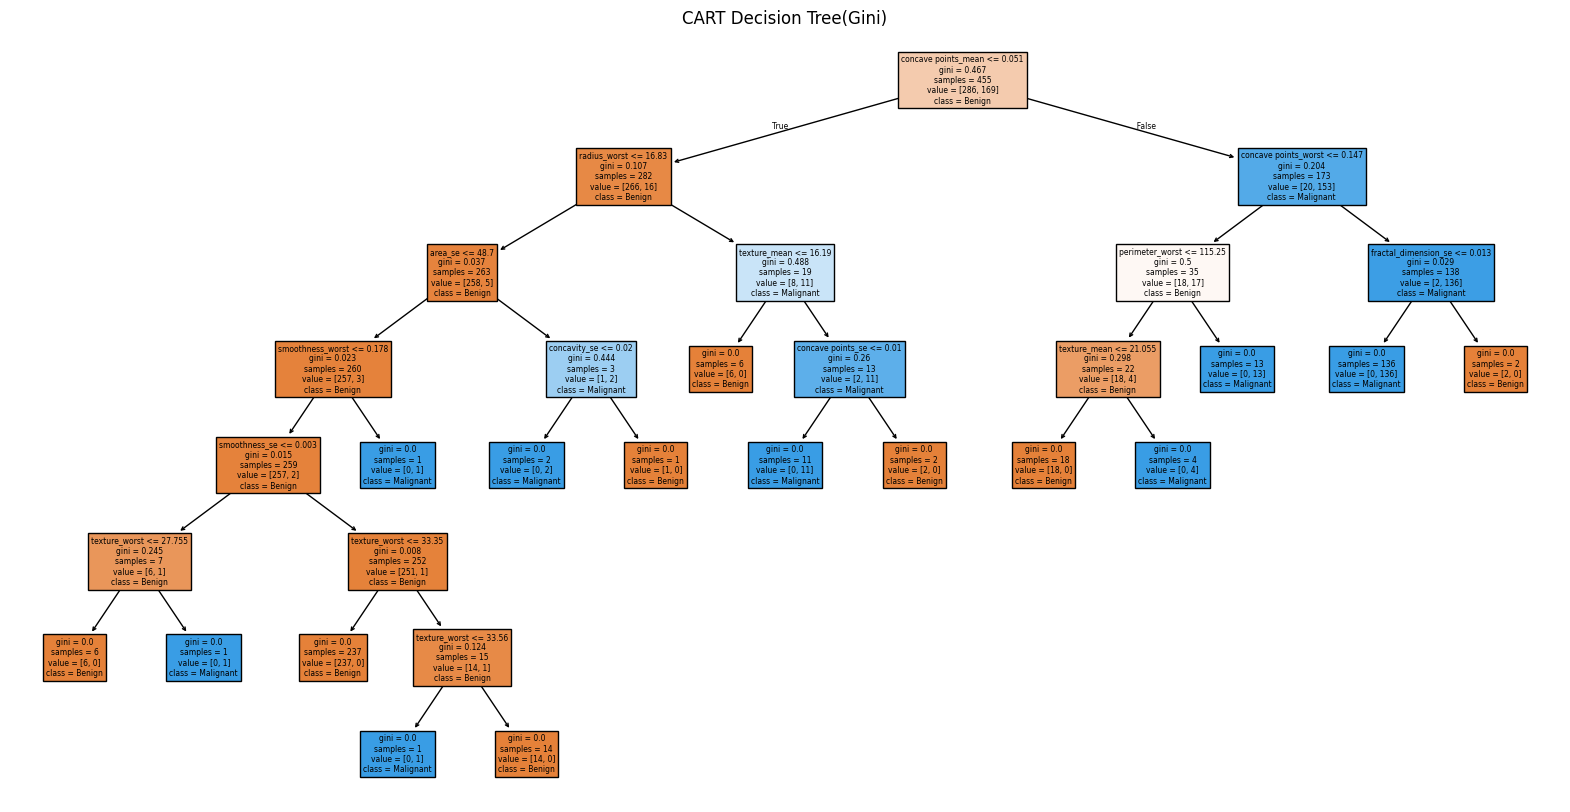


Performance Comparison Table:
           Model  Accuracy  Precision    Recall  F1 Score
0  ID3 (Entropy)  0.947368   0.974359  0.883721  0.926829
1           C4.5  0.947368   0.974359  0.883721  0.926829
2    CART (Gini)  0.947368   0.930233  0.930233  0.930233


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score

# Load and preprocess the dataset
df = pd.read_csv("Datasets/Breast_Cancer/data.csv")
df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

X = df.drop(columns=['diagnosis'])
y = df['diagnosis']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Function to Train & Evaluate Models ---
def train_and_evaluate_model(name, model):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"{name} Evaluation")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred)
    }

# --- ID3 (simulated using Entropy) ---
id3 = DecisionTreeClassifier(criterion='entropy', splitter='best', random_state=42)
id3_metrics = train_and_evaluate_model("ID3 (Entropy)", id3)

# --- C4.5 (Entropy with pruning, simulated same as ID3 for sklearn) ---
c45 = DecisionTreeClassifier(criterion='entropy', random_state=42)
c45_metrics = train_and_evaluate_model("C4.5", c45)

# --- CART (Gini) ---
cart = DecisionTreeClassifier(criterion='gini', random_state=42)
cart_metrics = train_and_evaluate_model("CART (Gini)", cart)
plt.figure(figsize=(20, 10))
plot_tree(cart, feature_names=X.columns, class_names=['Benign', 'Malignant'], filled=True)
plt.title("CART Decision Tree(Gini)")
plt.show()

# --- Comparison Table ---
comparison_df = pd.DataFrame([id3_metrics, c45_metrics, cart_metrics])
print("\nPerformance Comparison Table:")
print(comparison_df)

# Experiment 6(2)

In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load dataset
df = pd.read_csv("Datasets/Breast_Cancer/data.csv")
df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

# Feature and target split
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train k-NN model
k = 5
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train, y_train)

# Make predictions
y_pred = knn.predict(X_test)

# Evaluation
print("k-NN Classification Report")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Show correct and incorrect predictions
results = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
results['Match'] = results['Actual'] == results['Predicted']

# Correct predictions
print("\n✅ Correct Predictions:")
print(results[results['Match'] == True])

# Wrong predictions
print("\n❌ Wrong Predictions:")
print(results[results['Match'] == False])

k-NN Classification Report
Accuracy: 0.9473684210526315
              precision    recall  f1-score   support

           0       0.96      0.96      0.96        71
           1       0.93      0.93      0.93        43

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114


✅ Correct Predictions:
     Actual  Predicted  Match
0         0          0   True
1         1          1   True
2         1          1   True
3         0          0   True
4         0          0   True
..      ...        ...    ...
109       0          0   True
110       1          1   True
111       0          0   True
112       0          0   True
113       1          1   True

[108 rows x 3 columns]

❌ Wrong Predictions:
    Actual  Predicted  Match
8        0          1  False
13       1          0  False
20       1          0  False
52       0          1  False
77       1          0  False
91       0   

# Experiment 3

ID3 (Entropy-based Decision Tree) Evaluation
Accuracy: 0.9473684210526315
              precision    recall  f1-score   support

           0       0.93      0.99      0.96        71
           1       0.97      0.88      0.93        43

    accuracy                           0.95       114
   macro avg       0.95      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114



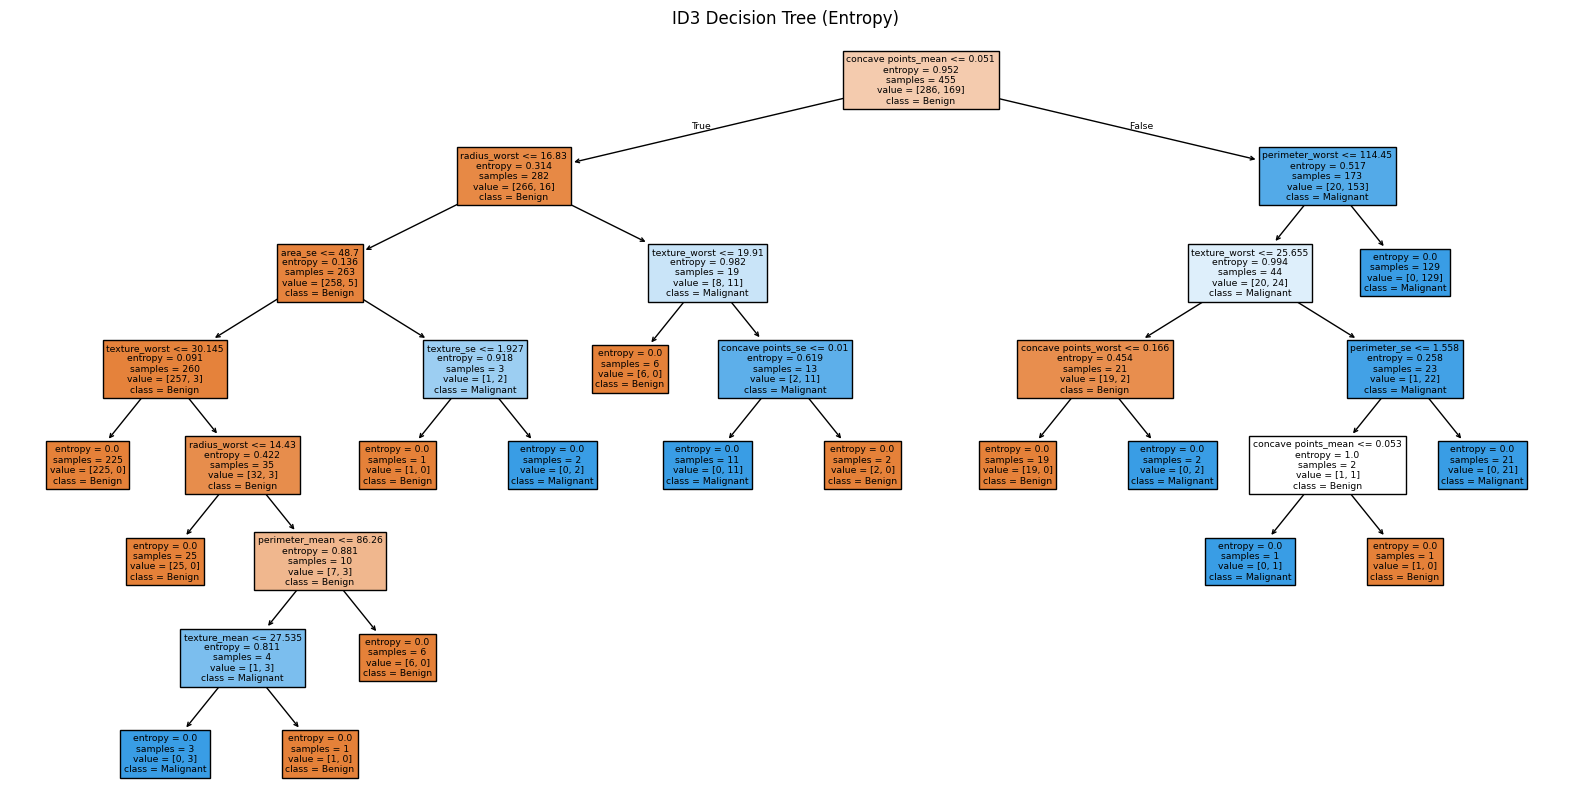


New Sample Prediction:
Predicted class for new sample: Benign


/Users/anaghbajpai/Desktop/myenv/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import numpy as np

# Load the dataset
df = pd.read_csv("Datasets/Breast_Cancer/data.csv")
df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

# Features and target
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Decision Tree using ID3 (Entropy)
id3_model = DecisionTreeClassifier(criterion='entropy', random_state=42)
id3_model.fit(X_train, y_train)

# Predict and evaluate
y_pred = id3_model.predict(X_test)
print("ID3 (Entropy-based Decision Tree) Evaluation")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Plot the decision tree
plt.figure(figsize=(20, 10))
plot_tree(id3_model, feature_names=X.columns, class_names=['Benign', 'Malignant'], filled=True)
plt.title("ID3 Decision Tree (Entropy)")
plt.show()

# --- Classify a new sample (use one row from X_test as an example) ---
new_sample = X_test.iloc[0].values.reshape(1, -1)
predicted_class = id3_model.predict(new_sample)[0]
print("\nNew Sample Prediction:")
print("Predicted class for new sample:", "Malignant" if predicted_class == 1 else "Benign")

# Experiment 7

In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# Load the dataset
df = pd.read_csv("Datasets/Breast_Cancer/data.csv")
df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')

# Encode diagnosis column: M = 1 (Malignant), B = 0 (Benign)
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

# Features and target
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature scaling (recommended for GaussianNB)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Initialize and train Naïve Bayes model
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# Predict on test data
y_pred = nb_model.predict(X_test)

# Evaluation
print("Naïve Bayes Classifier Evaluation")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=['Benign', 'Malignant']))

Naïve Bayes Classifier Evaluation
Accuracy: 0.9649122807017544
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        71
   Malignant       0.98      0.93      0.95        43

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



# Experiment 10

Linear Regression Performance:
Mean Absolute Error (MAE): 0.1969
Mean Squared Error (MSE): 0.0641
Root Mean Squared Error (RMSE): 0.2532
R² Score: 0.7271


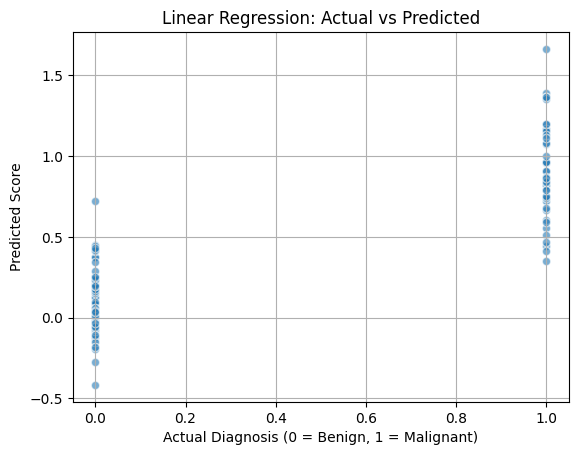

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

# Load the dataset
df = pd.read_csv("Datasets/Breast_Cancer/data.csv")
df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')
df = df.drop(columns=['Unnamed: 32'], errors='ignore')  # Drop extra unnamed column if present

# Encode diagnosis: M = 1, B = 0
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

# Features and target
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict
y_pred = lr_model.predict(X_test)

# Evaluation
print("Linear Regression Performance:")
print(f"Mean Absolute Error (MAE): {mean_absolute_error(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")

# Scatter plot of actual vs predicted
plt.scatter(y_test, y_pred, alpha=0.6, edgecolors='w')
plt.xlabel("Actual Diagnosis (0 = Benign, 1 = Malignant)")
plt.ylabel("Predicted Score")
plt.title("Linear Regression: Actual vs Predicted")
plt.grid(True)
plt.show()

# Experiment 9

Silhouette Score: 0.3434


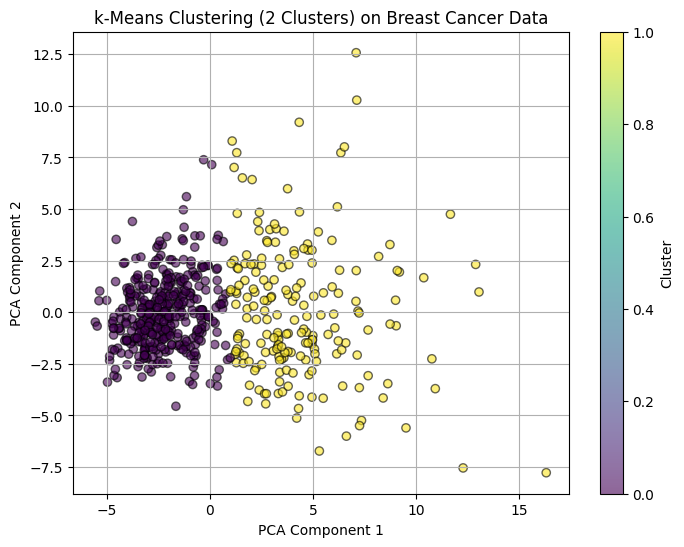


Cluster vs Actual Comparison:
Clustered As    0    1
Actual                
0             339   18
1              36  176


In [16]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("Datasets/Breast_Cancer/data.csv")
df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')
df = df.drop(columns=['Unnamed: 32'], errors='ignore')  # if exists

# Encode target (optional for comparison, not used in clustering)
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

# Features only (drop target)
X = df.drop(columns=['diagnosis'])

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply k-Means clustering
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Evaluate clustering quality using silhouette score
sil_score = silhouette_score(X_scaled, clusters)
print(f"Silhouette Score: {sil_score:.4f}")

# Visualize clusters using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', edgecolor='k', alpha=0.6)
plt.title("k-Means Clustering (2 Clusters) on Breast Cancer Data")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()

# Optional: Compare clusters with actual diagnosis
df['Cluster'] = clusters
comparison = pd.crosstab(df['diagnosis'], df['Cluster'], rownames=['Actual'], colnames=['Clustered As'])
print("\nCluster vs Actual Comparison:")
print(comparison)